In [124]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

from pde_packages import *

In [125]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

from pde_packages import *

from scipy.sparse import lil_matrix

def create_blank_stgrd_stokes_matrix(N):
    A = lil_matrix(((3*N-1)*(N-1), (3*N-1)*(N-1)))
    return A

def get_U_index(i, j, N):
    if i<0 or i>=N:
        print("Index out of bounds")
        return None
    if j<0.5 or j>=N-0.5:
        print("Index out of bounds. Perhaps you tried to index row 0? U starts at row 0.5.")
        return None
    
    #Make sure the x index is a whole number, and the y index is a half-integer.
    if not float(i).is_integer():
        print("Index out of bounds. i should be a whole number.")
        return None
    if not (j - 0.5).is_integer():
        print("Index out of bounds. j should be a half-integer.")
        return None
    
    #our x is going to be the fast index. Like reading a book row by row.
    return int(i + N * (j - 0.5))

def get_V_index(i, j, N):
    if i<0.5 or i>=N-0.5:
        raise ValueError("i index out of bounds for V grid")
    if j<0 or j>=N:
        raise ValueError("j index out of bounds for V grid")

    if not (i-0.5).is_integer():
        raise ValueError("i index must be a half-integer for V grid")
    if not j.is_integer():
        raise ValueError("j index must be an integer for V grid")

    return int((i-0.5) + (N-1)*j) + N*(N-1)

def get_P_index(i, j, N):
    if i<0.5 or i>=N-0.5:
        print("Index out of bounds. Perhaps you tried to index column 0? P starts at column 0.5.")
        return None
    if j<0.5 or j>=N-0.5:
        print("Index out of bounds. Perhaps you tried to index row 0? P starts at row 0.5.")
        return None

    if not (j-0.5).is_integer():
        print("Index out of bounds. P indices must be half-integers.")
        return None
    if not (i-0.5).is_integer():
        print("Index out of bounds. P indices must be half-integers.")
        return None

    return int(i-0.5 + (j-0.5)*(N-1)) + 2*N*(N-1)

def get_xy(i, j, N, x_0, x_N, y_0, y_N):
    x = x_0 + i * (x_N - x_0) / (N-1)
    y = y_0 + j * (y_N - y_0) / (N-1)
    return x, y

def laplacian_U(A, N, h, b, grad_squared_U, dxP, x_0, x_N, y_0, y_N, tpbdy, bmbdy):
    for j in range(0, N-1):
        #j for U are the 1/2 grid points.
        j+=0.5
        for i in range(0, N):

            #We should be using this no matter what:
            self_U_index = get_U_index(i, j, N)

            #If it's the very last column, we just set it equal to the value for the first column and continue.
            if i == N-1:
                A[self_U_index, self_U_index] = 1.0
                A[self_U_index, get_U_index(0, j, N)] = -1.0
                b[self_U_index] = 0.0
                continue

            A[self_U_index, self_U_index] += -4.0/h**2
            [x,y] = get_xy(i, j, N, x_0, x_N, y_0, y_N)
            b[self_U_index] =  grad_squared_U(x, y) - dxP(x,y)

            if i == 0:
                # Apply boundary condition for the left boundary of U
                # We don't do ghost points here, we do periodic conditions instead. So the i-1 index (outside of domain) wraps around to the last index.
                A[self_U_index, get_U_index(N-2, j, N)] = 1.0/h**2   #Left side value, wrapped around.
                A[self_U_index, get_U_index(i+1, j, N)] = 1.0/h**2   #Right side value, normal.
            else:
                A[self_U_index, get_U_index(i-1, j, N)] = 1.0/h**2
                A[self_U_index, get_U_index(i+1, j, N)] = 1.0/h**2
            
            # if j == 0.5:
            #     # Apply boundary condition for the bottom boundary of U
            #     #Note that the laplacian will still really describe this equation,
            #     #We just use a ghost point as one of the neighboring points in the laplacian.
            #     #Specifically, on the opposite side of the boundary, (u_self + u_ghost)/2 represents the value at the boundary.
            #     #Therefore, run the same laplacian as for the interior points, u_G becomes:
            #     #2(bdy - u_self) where 2*bdy goes to the rhs (b)
            #     A[self_U_index, self_U_index] -= 1.0/h**2
            #     b[self_U_index] += -2*bmbdy(x, y)/h**2
            #     A[self_U_index, get_U_index(i, j+1, N)] = 1.0/h**2
            # elif j == N-1.5:
            #     # Apply boundary condition for the top boundary of U
            #     A[self_U_index, get_U_index(i, j-1, N)] = 1.0/h**2
            #     A[self_U_index, self_U_index] -= 1.0/h**2
            #     b[self_U_index] += -2*tpbdy(x, y)/h**2

            if j == 0.5:
                A[self_U_index, self_U_index] += -3.0/h**2
                A[self_U_index, get_U_index(i, j+1, N)] = 2.0/h**2
                A[self_U_index, get_U_index(i, j+2, N)] = -(1/5)/h**2

                [x_bdy, y_bdy] = get_xy(i, 0, N, x_0, x_N, y_0, y_N)
                b[self_U_index] += -(16/5)*bmbdy(x_bdy, y_bdy)/h**2

            elif j == N-1.5:
                A[self_U_index, self_U_index] += -3.0/h**2
                A[self_U_index, get_U_index(i, j-1, N)] = 2.0/h**2
                A[self_U_index, get_U_index(i, j-2, N)] = -(1/5)/h**2

                [x_bdy, y_bdy] = get_xy(i, N-1, N, x_0, x_N, y_0, y_N)
                b[self_U_index] += -(16/5)*tpbdy(x_bdy, y_bdy)/h**2


            else:
                A[self_U_index, get_U_index(i, j-1, N)] = 1.0/h**2
                A[self_U_index, get_U_index(i, j+1, N)] = 1.0/h**2

            #Now we need to get the neighboring P indices for the current U point.
            if i == 0:
                A[self_U_index, get_P_index(N-1.5, j, N)] = 1.0/(h)
                A[self_U_index, get_P_index(i+0.5, j, N)] = -1.0/(h)
            # elif i == N-1:
            #     A[self_U_index, get_P_index(i-0.5, j, N)] = 1.0/(h)
            #     A[self_U_index, get_P_index(0.5, j, N)] = -1.0/(h)
            else:
                A[self_U_index, get_P_index(i-0.5, j, N)] = 1.0/(h)
                A[self_U_index, get_P_index(i+0.5, j, N)] = -1.0/(h)

def laplacian_V(A, N, h, b, grad_squared_V, dyP, x_0, x_N, y_0, y_N, tpbdy, bmbdy):
    for j in range(0, N):
        for i in range(0, N-1):
            i+=0.5
            self_V_index = get_V_index(i, j, N)
            [x,y] = get_xy(i, j, N, x_0, x_N, y_0, y_N)

            if j == 0:
                A[self_V_index, self_V_index] = 1
                b[self_V_index] = bmbdy(x, y)
            elif j == N-1:
                A[self_V_index, self_V_index] = 1
                b[self_V_index] = tpbdy(x, y)

            else:
                A[self_V_index, self_V_index] = -4.0/h**2
                [x,y] = get_xy(i, j, N, x_0, x_N, y_0, y_N)
                b[self_V_index] = grad_squared_V(x, y) - dyP(x, y)

                if i == 0.5:
                    A[self_V_index, get_V_index(N-1.5, j, N)] = 1.0/h**2
                    A[self_V_index, get_V_index(i+1, j, N)] = 1.0/h**2
                elif i == N-1.5:
                    A[self_V_index, get_V_index(i-1, j, N)] = 1.0/h**2
                    A[self_V_index, get_V_index(0.5, j, N)] = 1.0/h**2
                else:
                    A[self_V_index, get_V_index(i-1, j, N)] = 1.0/h**2
                    A[self_V_index, get_V_index(i+1, j, N)] = 1.0/h**2

                A[self_V_index, get_V_index(i, j-1, N)] = 1.0/h**2
                A[self_V_index, get_V_index(i, j+1, N)] = 1.0/h**2

                A[self_V_index, get_P_index(i, j-0.5, N)] = 1.0/(h)
                A[self_V_index, get_P_index(i, j+0.5, N)] = -1.0/(h)

def divergence(A, N, h, b):
    for j in range(0, N-1):
        j+=0.5
        for i in range(0, N-1):
            i+=0.5
            self_P_index = get_P_index(i, j, N)

            A[self_P_index, get_U_index(i+0.5, j, N)] = 1.0/(h)
            A[self_P_index, get_U_index(i-0.5, j, N)] = -1.0/(h)
            A[self_P_index, get_V_index(i, j+0.5, N)] = 1.0/(h)
            A[self_P_index, get_V_index(i, j-0.5, N)] = -1.0/(h)

            b[self_P_index] = 0

def test_gsU(x, y):
    return -8*np.pi**2*np.sin(2*np.pi*x)*np.sin(2*np.pi*y)

def test_gsV(x, y):
    return -4*np.pi**2*np.cos(2*np.pi*x)*(2*np.cos(2*np.pi*y)-1)

def test_dxP(x, y):
    return -2*np.pi*np.sin(2*np.pi*x)*np.sin(2*np.pi*y)

def test_dyP(x, y):
    return 2*np.pi*np.cos(2*np.pi*x)*np.cos(2*np.pi*y)

def test_tpbdy_U(x, y):
    return 0
def test_bmbdy_U(x, y):
    return 0

def test_tpbdy_V(x, y):
    return -3.5
def test_bmbdy_V(x, y):
    return -3.5

def break_uvp(x, N):
    assert len(x) == (3*N-1)*(N-1), "Error breaking into uvp expected different sized x"
    u = x[:(N-1)*N]
    v = x[(N-1)*N:2*(N-1)*N]
    p = x[2*(N-1)*N:]
    return u, v, p

def test_Uxy(x,y):
    return np.sin(2*np.pi*x)*np.sin(2*np.pi*y)

def test_Vxy(x,y):
    return -3.5 + np.cos(2*np.pi*x)*(np.cos(2*np.pi*y)-1)

def test_Pxy(x,y):
    return np.sin(2*np.pi*y)*np.cos(2*np.pi*x)

def get_real_U(x_real, N, U_func, x_0, x_N, y_0, y_N):
    for j in range(0, N-1):
        j += 0.5
        for i in range(0, N):
            self_U_index = get_U_index(i, j, N)
            x, y = get_xy(i, j, N, x_0, x_N, y_0, y_N)
            x_real[self_U_index] = U_func(x, y)
    return x_real

def get_real_V(x_real, N, V_func, x_0, x_N, y_0, y_N):
    for j in range(0,N):
        for i in range(0, N-1):
            i += 0.5
            self_V_index = get_V_index(i, j, N)
            x, y = get_xy(i, j, N, x_0, x_N, y_0, y_N)
            x_real[self_V_index] = V_func(x, y)
    return x_real

def get_real_P(x_real, N, P_func, x_0, x_N, y_0, y_N):
    for j in range(0, N-1):
        j += 0.5
        for i in range(0, N-1):
            i += 0.5
            self_P_index = get_P_index(i, j, N)
            x, y = get_xy(i, j, N, x_0, x_N, y_0, y_N)
            x_real[self_P_index] = P_func(x, y)
    return x_real

def interpret_x_for_graph(x, N):
    u = np.zeros((N-1, N-1))
    v = np.zeros((N-1, N-1))
    p = np.zeros((N-1, N-1))

    for j in range(0,N-1):
        j+=0.5
        for i in range(0,N-1):
            i+=0.5
            #Here we will interpolate to give the value of u and v at the midpoint of each cell.
            U_mid = (x[get_U_index(i-0.5, j, N)] + x[get_U_index(i+0.5, j, N)]) / 2
            V_mid = (x[get_V_index(i, j-0.5, N)] + x[get_V_index(i, j+0.5, N)]) / 2
            P = x[get_P_index(i, j, N)]
            #Here we could store or return U_mid and V_mid as needed
            u[int(j-0.5), int(i-0.5)] = U_mid
            v[int(j-0.5), int(i-0.5)] = V_mid
            p[int(j-0.5), int(i-0.5)] = P

    return u, v, p

In [126]:
N = 51
h = 1.0 / (N-1)

A = create_blank_stgrd_stokes_matrix(N)
b = np.zeros((A.shape[0],))

laplacian_U(A, N, h, b, test_gsU, test_dxP, 0, 1, 0, 1, test_tpbdy_U, test_bmbdy_U)
laplacian_V(A, N, h, b, test_gsV, test_dyP, 0, 1, 0, 1, test_tpbdy_V, test_bmbdy_V)
divergence(A, N, h, b)

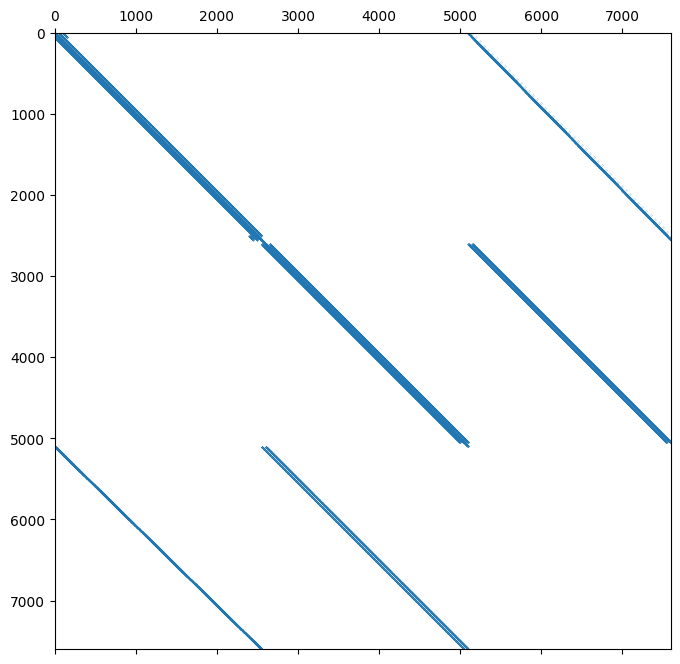

In [127]:
fig, ax = plt.subplots(figsize=(8, 8))

ax.spy(A, marker='.', markersize=0.3)

plt.show()

In [128]:
#So we cross our fingers and pray

x = sp.sparse.linalg.spsolve(A.tocsr(), b)

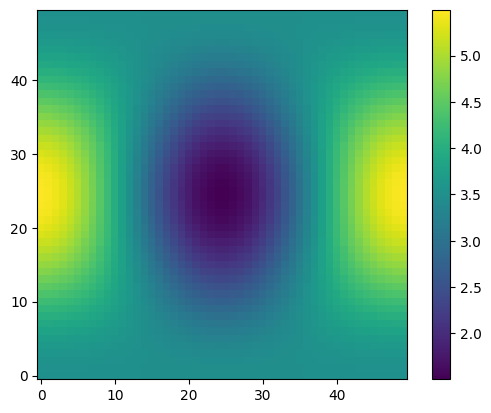

In [129]:
fig, ax = plt.subplots()

u, v, p = interpret_x_for_graph(x, N)

mag_u = np.sqrt(u**2 + v**2)

im = ax.imshow(mag_u, 
    origin="lower",
    )

cbar = fig.colorbar(im, ax=ax)
im.set_cmap("viridis")

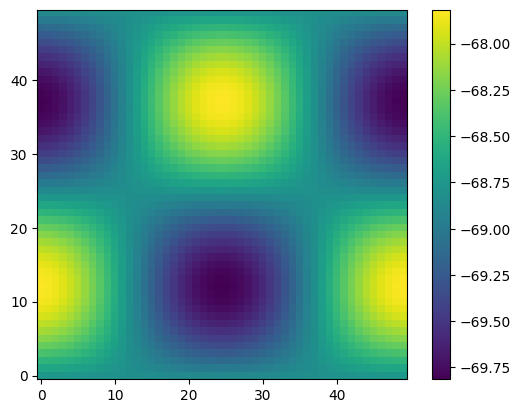

In [130]:
fig, ax = plt.subplots()

im = ax.imshow(p, 
    origin="lower",
    )

cbar = fig.colorbar(im, ax=ax)
im.set_cmap("viridis")

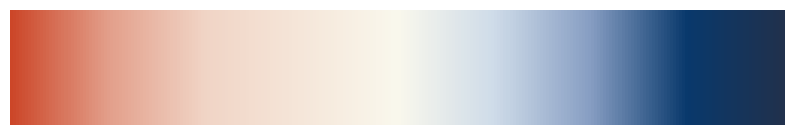

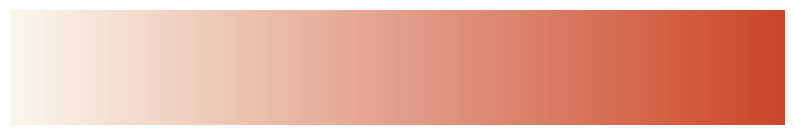

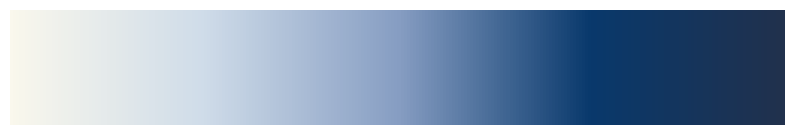

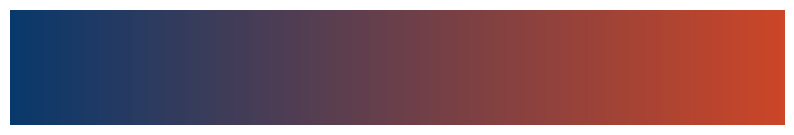

In [131]:
from matplotlib.colors import LinearSegmentedColormap

def show_gradient(cmap):
    gradient = np.linspace(0, 1, 256).reshape(1, -1)



    fig, ax = plt.subplots(figsize=(10, 1.5))

    ax.imshow(
        gradient,
        aspect="auto",
        cmap=cmap
    )

    ax.set_axis_off()

    plt.show()

cream = "#FAF8ED"

red_shades = LinearSegmentedColormap.from_list(
    "red_shades",
    [cream, colorado_red]
)

pale_red = red_shades(0.25)

mines_colors_div=[
    colorado_red,
    red_shades(0.5),
    red_shades(0.2),
    red_shades(0.1),
    cream,
    pale_blue,
    light_blue,
    blaster_blue,
    dark_blue
]

mines_cmap_div = LinearSegmentedColormap.from_list(
    "mines_cmap_div",
    mines_colors_div
)

show_gradient(mines_cmap_div)

# mines_colors_err=[
#     cream,
#     red_shades(0.1),
#     red_shades(0.2),
#     red_shades(0.5),
#     colorado_red
# ]

# mines_cmap_err = LinearSegmentedColormap.from_list(
#     "mines_cmap_err",
#     mines_colors_err
# )
# show_gradient(mines_cmap_err)
# show_gradient(red_shades)

mines_colors_vel_v=[
    cream,
    colorado_red
]

mines_cmap_vel_v = LinearSegmentedColormap.from_list(
    "mines_cmap_vel_v",
    mines_colors_vel_v
)
show_gradient(mines_cmap_vel_v)

mines_colors_vel_u=[
    cream,
    pale_blue,
    light_blue,
    blaster_blue,
    dark_blue
]

mines_cmap_vel_u = LinearSegmentedColormap.from_list(
    "mines_cmap_vel_u",
    mines_colors_vel_u
)
show_gradient(mines_cmap_vel_u)

mines_colors_change_hue_base=[
    blaster_blue,
    colorado_red
]

mines_cmap_change_hue_base = LinearSegmentedColormap.from_list(
    "mines_cmap_change_hue_base",
    mines_colors_change_hue_base
)

mines_colors_change_hue_scaled=[
    mines_cmap_change_hue_base(0),
    # mines_cmap_change_hue_base(0.35),
    # mines_cmap_change_hue_base(0.5),
    # mines_cmap_change_hue_base(0.65),
    mines_cmap_change_hue_base(1.0),
]

mines_cmap_change_hue_scaled = LinearSegmentedColormap.from_list(
    "mines_cmap_change_hue_scaled",
    mines_colors_change_hue_scaled
)
show_gradient(mines_cmap_change_hue_scaled)


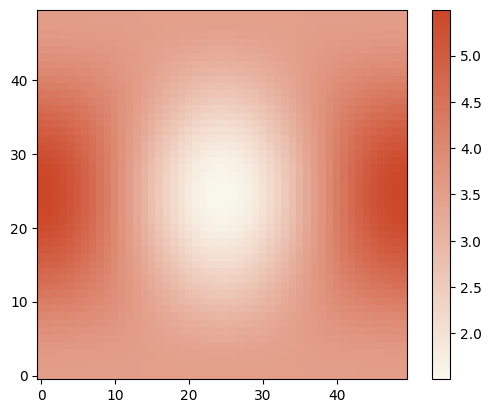

In [132]:
fig, ax = plt.subplots()

im = ax.imshow(mag_u, 
    origin="lower",
    )

cbar = fig.colorbar(im, ax=ax)
im.set_cmap(mines_cmap_vel_v)

In [157]:
from matplotlib.colors import to_rgba

max_v = np.max(np.abs(v))
max_u = np.max(np.abs(u))
max_mag = np.max(np.abs(u)**2 + np.abs(v)**2)

def vector_to_color(u, v, max_u, max_v, max_mag, hue_cmap, normalize_colors=False):
    cream_rgba = to_rgba(cream)
    base_colors = np.empty((u.shape[0], u.shape[1], 4))
    base_colors[:] = cream_rgba

    # Normalize magnitudes to [0, 1]
    U = np.abs(u)/max_u
    V = np.abs(v)/max_v
    magu = np.abs(u)**2 + np.abs(v)**2
    magu = (magu / max_mag)
    magu_Normalized = (np.abs(U)**2 + np.abs(V)**2)

    # Example colors -- replace with Mines colors
    color_u = mines_cmap_vel_u(U)
    color_v = mines_cmap_vel_v(V)

    #Change the hue based on the direction of the vector
    if not normalize_colors:
        hue_scale = np.arctan2(np.abs(v), np.abs(u)) / (np.pi / 2)
        color_c = hue_cmap(hue_scale)
        cream_influence = 1 - magu
        hue_influence = magu
    else:
        hue_scale = np.arctan2(np.abs(V), np.abs(U)) / (np.pi / 2)
        color_c = hue_cmap(hue_scale)
        cream_influence = 1 - magu_Normalized
        hue_influence = magu_Normalized

    # #For now. Revert later. Need to check arctan2 behavior and correct hue determination.
    # cream_influence = np.zeros_like(u)
    # hue_influence = np.ones_like(u)

    combined_colors = cream_influence[..., np.newaxis] * base_colors + hue_influence[..., np.newaxis] * color_c

    #Scale the saturation based on the magnitude of the vector
    #color_c

    return color_u, color_v, color_c, magu, combined_colors

color_u, color_v, color_c, magu, combined_colors = vector_to_color(u, v, max_u, max_v, max_mag, mines_cmap_change_hue_scaled, normalize_colors=True)

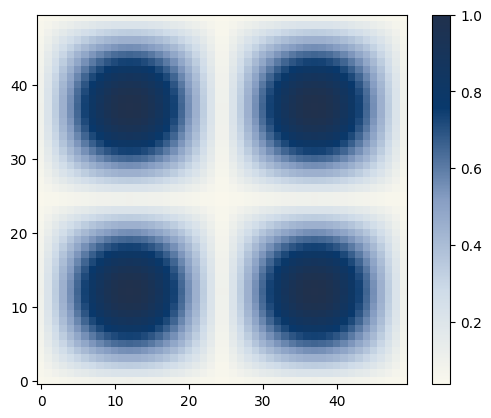

In [134]:
fig, ax = plt.subplots()

im = ax.imshow(color_u, 
    origin="lower",
    )

cbar = fig.colorbar(im, ax=ax)
im.set_cmap(mines_cmap_vel_u)

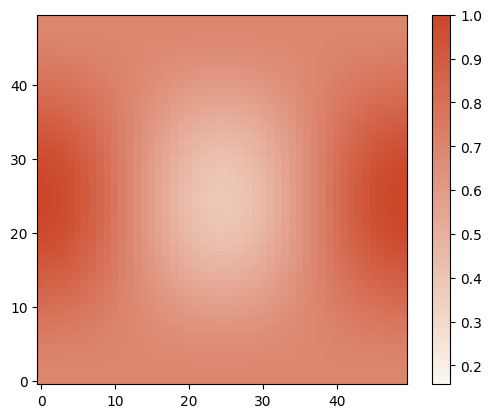

In [135]:
fig, ax = plt.subplots()

im = ax.imshow(color_v, 
    origin="lower",
    )

cbar = fig.colorbar(im, ax=ax)
im.set_cmap(mines_cmap_vel_v)

In [142]:
combined_colors

array([[[0.92785895, 0.77253515, 0.70841104, 1.        ],
        [0.92612641, 0.77236724, 0.70895138, 1.        ],
        [0.92523876, 0.77220686, 0.70913767, 1.        ],
        ...,
        [0.92523876, 0.77220686, 0.70913767, 1.        ],
        [0.92612641, 0.77236724, 0.70895138, 1.        ],
        [0.92785895, 0.77253515, 0.70841104, 1.        ]],

       [[0.92650432, 0.7706208 , 0.70666203, 1.        ],
        [0.92115511, 0.76977024, 0.70792584, 1.        ],
        [0.91563047, 0.76844669, 0.70868906, 1.        ],
        ...,
        [0.91563047, 0.76844669, 0.70868906, 1.        ],
        [0.92115511, 0.76977024, 0.70792584, 1.        ],
        [0.92650432, 0.7706208 , 0.70666203, 1.        ]],

       [[0.92374952, 0.76679726, 0.70318987, 1.        ],
        [0.91448362, 0.76483229, 0.70478033, 1.        ],
        [0.9055372 , 0.76163024, 0.70472688, 1.        ],
        ...,
        [0.9055372 , 0.76163024, 0.70472688, 1.        ],
        [0.91448362, 0.764832

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.06382918922961456..1.0].


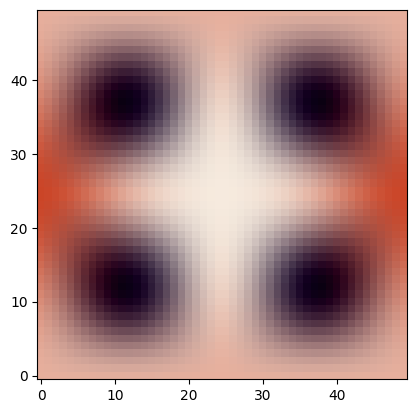

In [158]:
fig, ax = plt.subplots()

im = ax.imshow(combined_colors, 
    origin="lower",
    )

# cbar = fig.colorbar(im, ax=ax)
# im.set_cmap(mines_cmap_vel_u)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.4743098808150711..1.0].


[[0.         0.02039472 0.04078944 ... 0.95855176 0.97894648 0.9993412 ]
 [0.         0.02039472 0.04078944 ... 0.95855176 0.97894648 0.9993412 ]
 [0.         0.02039472 0.04078944 ... 0.95855176 0.97894648 0.9993412 ]
 ...
 [0.         0.02039472 0.04078944 ... 0.95855176 0.97894648 0.9993412 ]
 [0.         0.02039472 0.04078944 ... 0.95855176 0.97894648 0.9993412 ]
 [0.         0.02039472 0.04078944 ... 0.95855176 0.97894648 0.9993412 ]]
[[0.         0.         0.         ... 0.         0.         0.        ]
 [0.11213759 0.11213759 0.11213759 ... 0.11213759 0.11213759 0.11213759]
 [0.22427518 0.22427518 0.22427518 ... 0.22427518 0.22427518 0.22427518]
 ...
 [5.27046674 5.27046674 5.27046674 ... 5.27046674 5.27046674 5.27046674]
 [5.38260433 5.38260433 5.38260433 ... 5.38260433 5.38260433 5.38260433]
 [5.49474192 5.49474192 5.49474192 ... 5.49474192 5.49474192 5.49474192]]


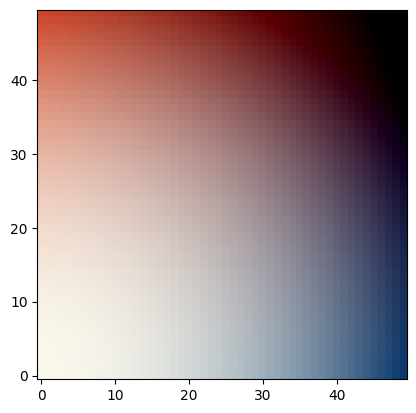

In [159]:
max_val_u = np.max(np.abs(u))
max_val_v = np.max(np.abs(v))

def cmap_test_u_v(N, max_u, max_v):
    u = np.linspace(0, max_u, N)
    v = np.linspace(0, max_v, N)
    U, V = np.meshgrid(u, v)
    return U, V

test_U, test_V = cmap_test_u_v(50, max_val_u, max_val_v)

print(test_U)
print(test_V)

test_u, test_v, test_c, test_magu, test_combined_colors = vector_to_color(test_U, test_V, max_u, max_v, max_mag, mines_cmap_change_hue_scaled, normalize_colors=True)

fig, ax = plt.subplots()

im = ax.imshow(test_combined_colors, 
    origin="lower",
)
plt.show()

In [139]:
def test_Uxy(x,y):
    return np.sin(2*np.pi*x)*np.sin(2*np.pi*y)

def test_Vxy(x,y):
    return -3.5 + np.cos(2*np.pi*x)*(np.cos(2*np.pi*y)-1)

def test_Pxy(x,y):
    return np.sin(2*np.pi*y)*np.cos(2*np.pi*x)

def get_real_test_sol(Uxy, Vxy, Pxy, N, h, x_0, x_N, y_0, y_N):
    U = np.zeros((N-1, N-1))
    V = np.zeros((N-1, N-1))
    P = np.zeros((N-1, N-1))

    for j in range(0,N-1):
        j+=0.5
        for i in range(0,N-1):
            i+=0.5
            [x,y] = get_xy(i, j, N, x_0, x_N, y_0, y_N)
            U[int(j-0.5),int(i-0.5)] = Uxy(x,y)
            V[int(j-0.5),int(i-0.5)] = Vxy(x,y)
            P[int(j-0.5),int(i-0.5)] = Pxy(x,y)

    return U, V, P

test_U, test_V, test_P = get_real_test_sol(test_Uxy, test_Vxy, test_Pxy, N, h, 0,1,0,1)



Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.06382918922961456..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.4743098808150711..1.0].


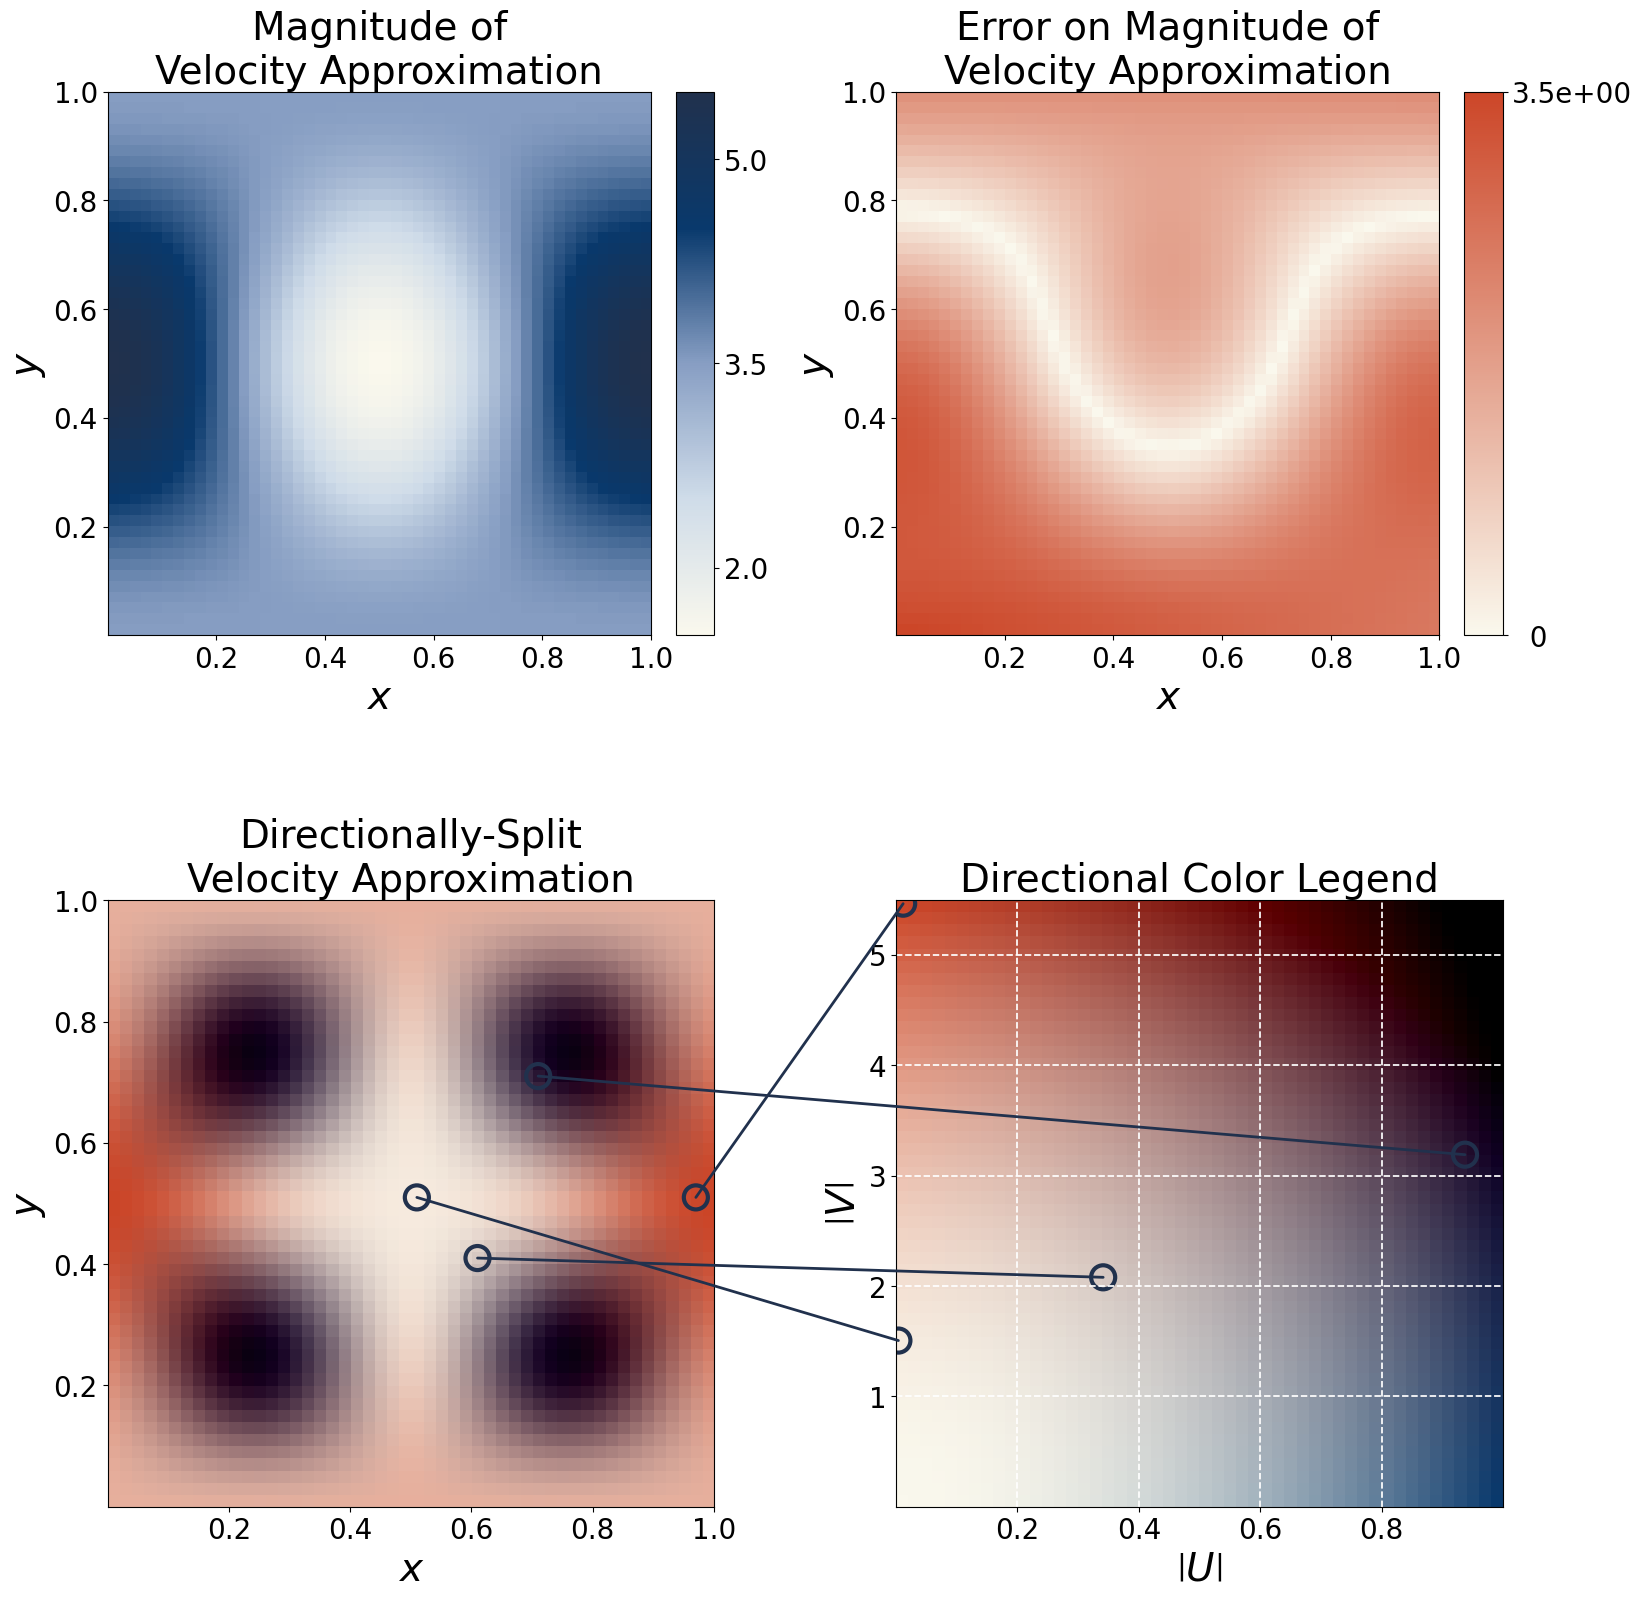

In [160]:
#Full beautiful figure mode

from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.patches import ConnectionPatch

x = np.linspace(0, 1, N)
y = np.linspace(0, 1, N)

fig, ax = plt.subplots(2, 2, figsize=(18, 20))

im0 = ax[0, 0].imshow(np.sqrt(u**2 + v**2),
    origin="lower",
    cmap = mines_cmap_vel_u,
    extent=[0, 1, 0, 1],
    )

im1 = ax[1, 0].imshow(combined_colors, 
    origin="lower",
    extent=[0, 1, 0, 1],
    )

im2 = ax[0, 1].imshow(np.abs(np.sqrt(test_U**2 + test_V**2)-np.sqrt(u**2 + v**2)),
    origin="lower",
    cmap = mines_cmap_vel_v,
    extent=[0, 1, 0, 1],
    )

im3 = ax[1, 1].imshow(test_combined_colors, 
    origin="lower",
    extent = [0, max_val_u, 0, max_val_v],
    aspect="auto"
    )

ax[0, 0].set_title("Magnitude of\nVelocity Approximation")
ax[0, 0].title.set_fontsize(28)
ax[0, 0].set_xticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax[0, 0].set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax[0, 0].tick_params(labelsize=20)
ax[0, 0].set_xlabel("$x$", fontsize=28)
ax[0, 0].set_ylabel("$y$", fontsize=28)
ax[1, 0].set_title("Directionally-Split\nVelocity Approximation")
ax[1, 0].title.set_fontsize(28)
ax[1, 0].set_xticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax[1, 0].set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax[1, 0].tick_params(labelsize=20)
ax[1, 0].set_xlabel("$x$", fontsize=28)
ax[1, 0].set_ylabel("$y$", fontsize=28)
ax[0, 1].set_title("Error on Magnitude of\nVelocity Approximation")
ax[0, 1].title.set_fontsize(28)
ax[0, 1].set_xticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax[0, 1].set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax[0, 1].tick_params(labelsize=20)
ax[0, 1].set_xlabel("$x$", fontsize=28)
ax[0, 1].set_ylabel("$y$", fontsize=28)
ax[1, 1].set_title("Directional Color Legend")
ax[1, 1].title.set_fontsize(28)
ax[1, 1].set_xticks([0.2, 0.4, 0.6, 0.8])
ax[1, 1].set_yticks([1, 2, 3, 4, 5])
ax[1, 1].tick_params(labelsize=20)
ax[1, 1].set_xlabel("$\\left| U \\right|$", fontsize=28)
ax[1, 1].set_ylabel("$\\left| V \\right|$", fontsize=28)

ax[1, 1].grid(
    True,
    linestyle="--",
    linewidth=1.25,
    alpha=1,
    color="white"
)

#Helps keep plot axis labels from colliding, if necessary
fig.subplots_adjust(wspace=0.3)   # modest

#---Create colorbar for approx and tune it-----
divider = make_axes_locatable(ax[0, 0])
cax = divider.append_axes("right", size="7%", pad=0.25)
cb_approx = fig.colorbar(im0, cax=cax)
cb_approx.ax.tick_params(labelsize=20)
cb_approx.set_ticks([2.0, 3.5, 5.0])
#-----Create colorbar for error and tune it-----
divider_err = make_axes_locatable(ax[0, 1])
cax_err = divider_err.append_axes("right", size="7%", pad=0.25)
cb_err = fig.colorbar(im2, cax=cax_err)
cb_err.ax.tick_params(labelsize=20)
cb_err.set_ticks([np.min(np.abs(np.sqrt(test_U**2 + test_V**2)-np.sqrt(u**2 + v**2))), 
                  np.max(np.abs(np.sqrt(test_U**2 + test_V**2)-np.sqrt(u**2 + v**2)))])
cb_err.set_ticklabels(["  0", f"{np.max(np.abs(np.sqrt(test_U**2 + test_V**2)-np.sqrt(u**2 + v**2))):.1e}"])

#Set height of bottom two equal to each other.
pos_left  = ax[1, 0].get_position()
pos_right = ax[1, 1].get_position()

ax[1, 1].set_position([
    pos_right.x0,     # keep legend's horizontal position
    pos_left.y0,      # copy bottom from left plot
    pos_right.width,  # keep legend's width
    pos_left.height   # copy height from left plot
])

x_red = 0.97
y_red = 0.51
i_red = 48.5
j_red = 25.5

ax[1, 0].scatter(
    x_red,
    y_red,
    facecolors="none",
    edgecolors=dark_blue,
    s=300,
    linewidths=3
)

ax[1, 1].scatter(
    np.abs(u[int(j_red-0.5), int(i_red-0.5)]),
    np.abs(v[int(j_red-0.5), int(i_red-0.5)]),
    facecolors="none",
    edgecolors=dark_blue,
    s=300,
    linewidths=3
)

x_purple = 0.71
y_purple = 0.71
i_purple = 35.5
j_purple = 35.5

ax[1, 0].scatter(
    x_purple,
    y_purple,
    facecolors="none",
    edgecolors=dark_blue,
    s=300,
    linewidths=3
)

ax[1, 1].scatter(
    np.abs(u[int(j_purple-0.5), int(i_purple-0.5)]),
    np.abs(v[int(j_purple-0.5), int(i_purple-0.5)]),
    facecolors="none",
    edgecolors=dark_blue,
    s=300,
    linewidths=3
)

x_blue = 0.61
y_blue = 0.41
i_blue = 30.5
j_blue = 20.5

ax[1, 0].scatter(
    x_blue,
    y_blue,
    facecolors="none",
    edgecolors=dark_blue,
    s=300,
    linewidths=3
)

ax[1, 1].scatter(
    np.abs(u[int(j_blue-0.5), int(i_blue-0.5)]),
    np.abs(v[int(j_blue-0.5), int(i_blue-0.5)]),
    facecolors="none",
    edgecolors=dark_blue,
    s=300,
    linewidths=3
)

x_cream = 0.51
y_cream = 0.51
i_cream = 25.5
j_cream = 25.5

ax[1, 0].scatter(
    x_cream,
    y_cream,
    facecolors="none",
    edgecolors=dark_blue,
    s=300,
    linewidths=3
)

ax[1, 1].scatter(
    np.abs(u[int(j_cream-0.5), int(i_cream-0.5)]),
    np.abs(v[int(j_cream-0.5), int(i_cream-0.5)]),
    facecolors="none",
    edgecolors=dark_blue,
    s=300,
    linewidths=3
)

x_dots = [x_red, x_purple, x_blue, x_cream]
y_dots = [y_red, y_purple, y_blue, y_cream]
u_vals = [np.abs(u[int(j-0.5), int(i-0.5)]) for i, j in [(i_red, j_red), (i_purple, j_purple), (i_blue, j_blue), (i_cream, j_cream)]]
v_vals = [np.abs(v[int(j-0.5), int(i-0.5)]) for i, j in [(i_red, j_red), (i_purple, j_purple), (i_blue, j_blue), (i_cream, j_cream)]]

for x0, y0, u0, v0 in zip(x_dots, y_dots, u_vals, v_vals):
    con = ConnectionPatch(
        xyA=(x0, y0), xyB=(u0, v0),
        coordsA="data", coordsB="data",
        axesA=ax[1, 0], axesB=ax[1, 1],
        color = dark_blue,
        linewidth = 2,
        alpha = 1,
        # connectionstyle="arc3,rad=0.3"
    )
    fig.add_artist(con)

# cbar = fig.colorbar(im, ax=ax)
# im.set_cmap(mines_cmap_vel_u)

#save the figure
# fig.savefig("stokes_plot_better_hues.png")

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.06382918922961456..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.4743098808150711..1.0].


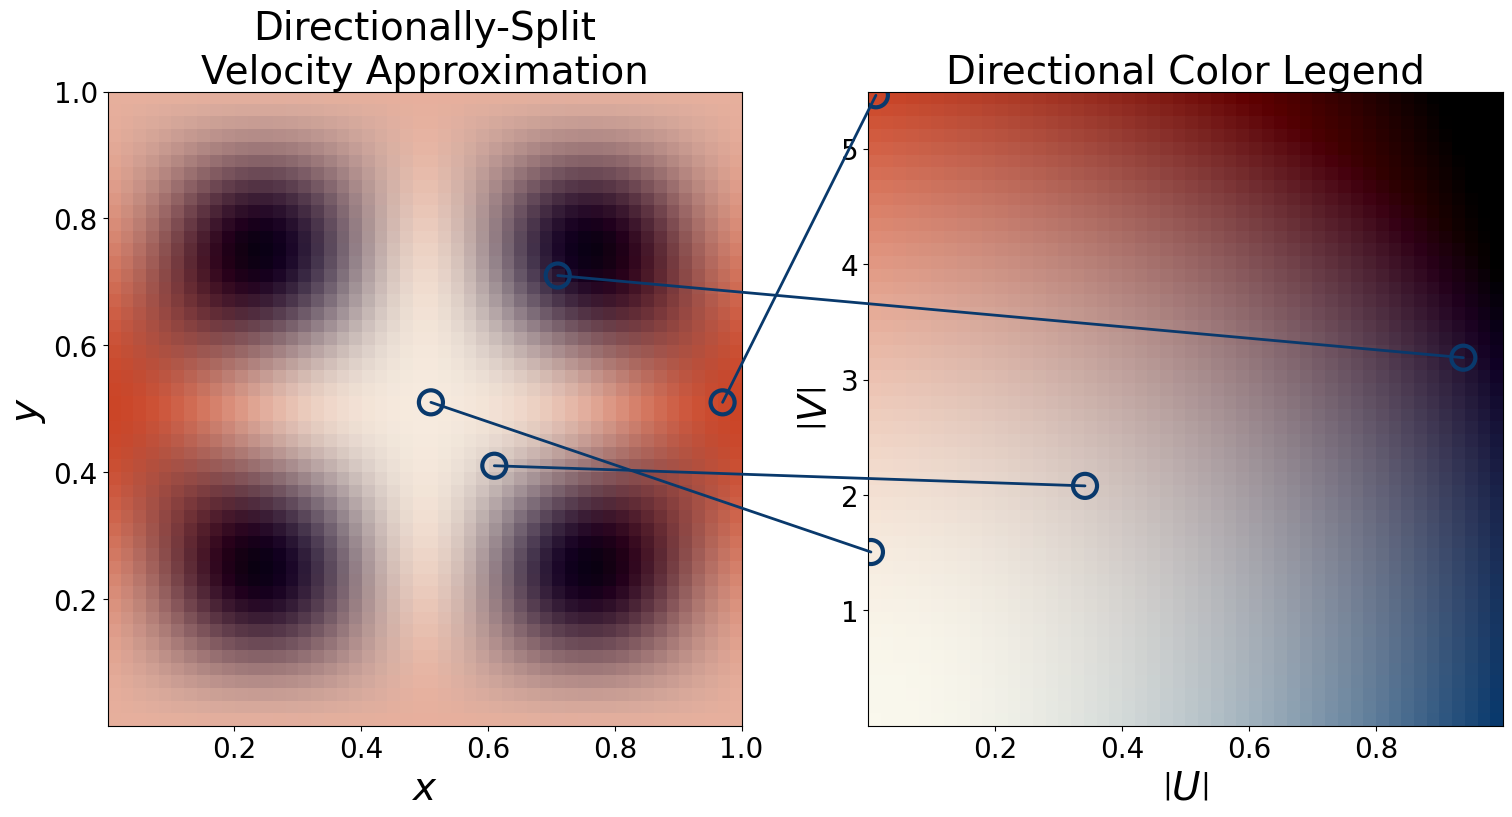

In [166]:
#Full beautiful figure mode

from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.patches import ConnectionPatch

x = np.linspace(0, 1, N)
y = np.linspace(0, 1, N)

fig, ax = plt.subplots(1, 2, figsize=(18, 10))

im1 = ax[0].imshow(combined_colors, 
    origin="lower",
    extent=[0, 1, 0, 1],
    )

im3 = ax[1].imshow(test_combined_colors, 
    origin="lower",
    extent = [0, max_val_u, 0, max_val_v],
    aspect="auto"
    )


ax[0].set_title("Directionally-Split\nVelocity Approximation")
ax[0].title.set_fontsize(28)
ax[0].set_xticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax[0].set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax[0].tick_params(labelsize=20)
ax[0].set_xlabel("$x$", fontsize=28)
ax[0].set_ylabel("$y$", fontsize=28)

ax[1].set_title("Directional Color Legend")
ax[1].title.set_fontsize(28)
ax[1].set_xticks([0.2, 0.4, 0.6, 0.8])
ax[1].set_yticks([1, 2, 3, 4, 5])
ax[1].tick_params(labelsize=20)
ax[1].set_xlabel("$\\left| U \\right|$", fontsize=28)
ax[1].set_ylabel("$\\left| V \\right|$", fontsize=28)

#Set height of bottom two equal to each other.
pos_left  = ax[0].get_position()
pos_right = ax[1].get_position()

ax[1].set_position([
    pos_right.x0,     # keep legend's horizontal position
    pos_left.y0,      # copy bottom from left plot
    pos_right.width,  # keep legend's width
    pos_left.height   # copy height from left plot
])

x_red = 0.97
y_red = 0.51
i_red = 48.5
j_red = 25.5

ax[0].scatter(
    x_red,
    y_red,
    facecolors="none",
    edgecolors=blaster_blue,
    s=300,
    linewidths=3
)

ax[1].scatter(
    np.abs(u[int(j_red-0.5), int(i_red-0.5)]),
    np.abs(v[int(j_red-0.5), int(i_red-0.5)]),
    facecolors="none",
    edgecolors=blaster_blue,
    s=300,
    linewidths=3
)

x_purple = 0.71
y_purple = 0.71
i_purple = 35.5
j_purple = 35.5

ax[0].scatter(
    x_purple,
    y_purple,
    facecolors="none",
    edgecolors=blaster_blue,
    s=300,
    linewidths=3
)

ax[1].scatter(
    np.abs(u[int(j_purple-0.5), int(i_purple-0.5)]),
    np.abs(v[int(j_purple-0.5), int(i_purple-0.5)]),
    facecolors="none",
    edgecolors=blaster_blue,
    s=300,
    linewidths=3
)

x_blue = 0.61
y_blue = 0.41
i_blue = 30.5
j_blue = 20.5

ax[0].scatter(
    x_blue,
    y_blue,
    facecolors="none",
    edgecolors=blaster_blue,
    s=300,
    linewidths=3
)

ax[1].scatter(
    np.abs(u[int(j_blue-0.5), int(i_blue-0.5)]),
    np.abs(v[int(j_blue-0.5), int(i_blue-0.5)]),
    facecolors="none",
    edgecolors=blaster_blue,
    s=300,
    linewidths=3
)

x_cream = 0.51
y_cream = 0.51
i_cream = 25.5
j_cream = 25.5

ax[0].scatter(
    x_cream,
    y_cream,
    facecolors="none",
    edgecolors=blaster_blue,
    s=300,
    linewidths=3
)

ax[1].scatter(
    np.abs(u[int(j_cream-0.5), int(i_cream-0.5)]),
    np.abs(v[int(j_cream-0.5), int(i_cream-0.5)]),
    facecolors="none",
    edgecolors=blaster_blue,
    s=300,
    linewidths=3
)

x_dots = [x_red, x_purple, x_blue, x_cream]
y_dots = [y_red, y_purple, y_blue, y_cream]
u_vals = [np.abs(u[int(j-0.5), int(i-0.5)]) for i, j in [(i_red, j_red), (i_purple, j_purple), (i_blue, j_blue), (i_cream, j_cream)]]
v_vals = [np.abs(v[int(j-0.5), int(i-0.5)]) for i, j in [(i_red, j_red), (i_purple, j_purple), (i_blue, j_blue), (i_cream, j_cream)]]

for x0, y0, u0, v0 in zip(x_dots, y_dots, u_vals, v_vals):
    con = ConnectionPatch(
        xyA=(x0, y0), xyB=(u0, v0),
        coordsA="data", coordsB="data",
        axesA=ax[0], axesB=ax[1],
        color = blaster_blue,
        linewidth = 2,
        alpha = 1,
        # connectionstyle="arc3,rad=0.3"
    )
    fig.add_artist(con)

# cbar = fig.colorbar(im, ax=ax)
# im.set_cmap(mines_cmap_vel_u)

#save the figure
fig.savefig("stokes_plot_better_hues.png")

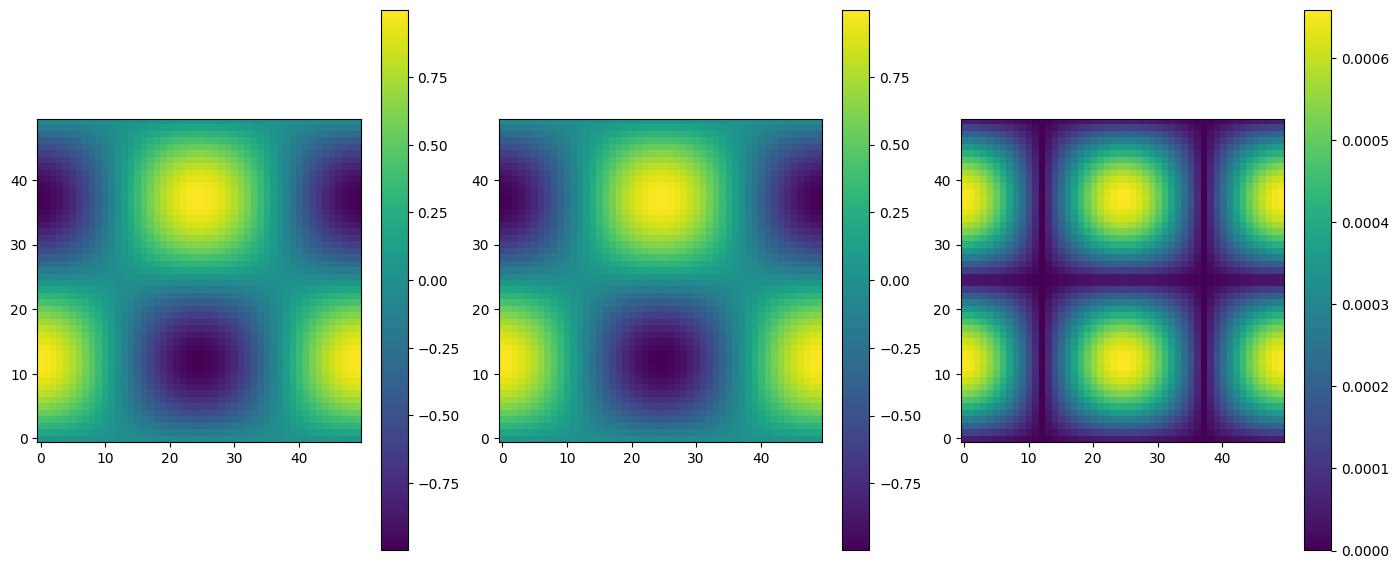

In [101]:
#Plot the approximated error and the exact solution

fig, ax = plt.subplots(1, 3, figsize=(14, 6))
fig.tight_layout()

p = p-np.mean(p)

im0 = ax[0].imshow(p, origin='lower', cmap='viridis')
im1 = ax[1].imshow(test_P, origin='lower', cmap='viridis')
im2 = ax[2].imshow(np.abs(test_P- p), origin='lower', cmap='viridis')

fig.colorbar(im0, ax=ax[0])
fig.colorbar(im1, ax=ax[1])
fig.colorbar(im2, ax=ax[2])

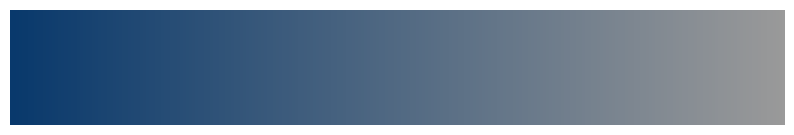

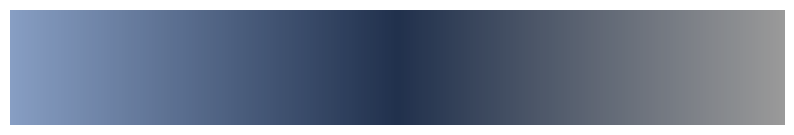

In [102]:
mines_silver = "#9A9A9A"

blaster_colors_hue=[
    blaster_blue,
    mines_silver
]

blaster_cmap = LinearSegmentedColormap.from_list("blaster_cmap", blaster_colors_hue)
show_gradient(blaster_cmap)

blaster_colors_hue_scaled = [
    light_blue,
    dark_blue,
    mines_silver
]

blaster_cmap_scaled = LinearSegmentedColormap.from_list("blaster_cmap_scaled", blaster_colors_hue_scaled)
show_gradient(blaster_cmap_scaled)


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.7178469819300268..1.0].


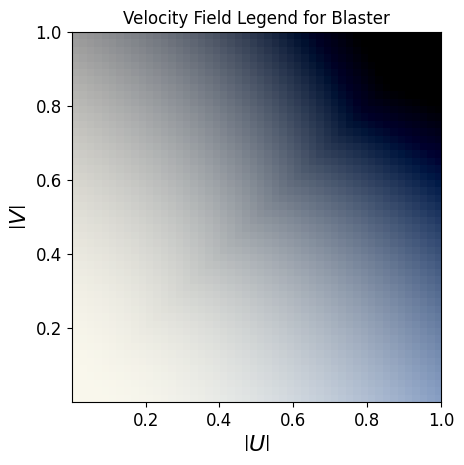

In [172]:
example_u, example_v = cmap_test_u_v(50, 1, 1)

example_u, example_v, example_c, example_magu, example_combined_colors = vector_to_color(example_u, example_v, 1, 1, 1, blaster_cmap_scaled)

fig, ax = plt.subplots()
im = ax.imshow(example_combined_colors, origin="lower", extent=[0,1,0,1])

ax.set_xlabel("$\\left| U \\right|$", fontsize=16)
ax.set_ylabel("$\\left| V \\right|$", fontsize=16)
ax.set_xticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.tick_params(labelsize=12)
ax.set_title("Velocity Field Legend for Blaster")

plt.show()

fig.savefig("blaster_colormap.png")

In [104]:
import pymupdf
import numpy as np
from PIL import Image
import io

# Read SVG
with open("colorado-mines.svg", "rb") as f:
    svg_data = f.read()

# Open SVG directly
doc = pymupdf.open(stream=svg_data, filetype="svg")
page = doc[0]

# Render at high resolution
pix = page.get_pixmap(matrix=pymupdf.Matrix(4, 4), alpha=True)

# Convert to Pillow / numpy
img = Image.open(io.BytesIO(pix.tobytes("png"))).convert("RGBA")
rgba = np.asarray(img) / 255.0
blaster_rgba = rgba[::-1, :, :]

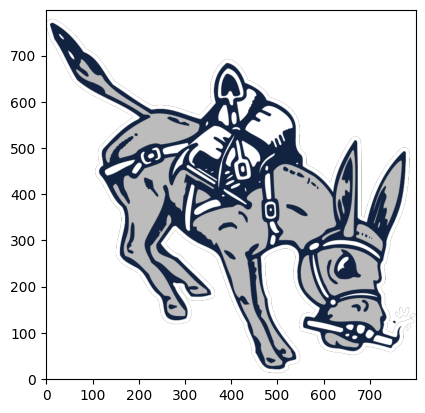

In [105]:
plt.imshow(blaster_rgba, origin='lower')

In [106]:
#put the image on a white background
white_background = np.ones_like(blaster_rgba)
blaster_on_white = np.where(blaster_rgba[..., 3:] == 0, white_background, blaster_rgba)

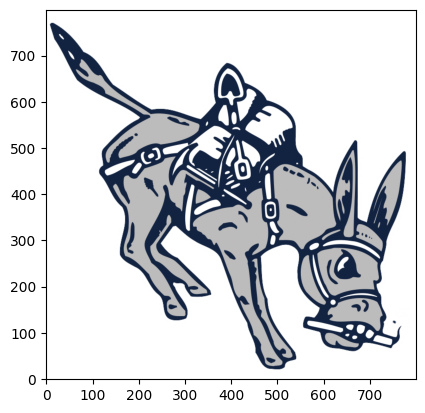

In [107]:
plt.imshow(blaster_on_white, origin='lower')

In [108]:
def pixelize_image(image, N):
    pixels_x = image.shape[1]
    pixels_y = image.shape[0]
    pixelized_image = np.zeros([N-1, N-1, image.shape[2]])
    for i in range(0, N-1): #This is actually going to increment the coluns, wierdly enough.
        for j in range(0, N-1): #This is actually going to increment the rows. This is because the first index of the image array corresponds to the row.
            x_start = pixels_x * i // (N-1)
            x_end = pixels_x * (i+1) // (N-1)
            y_start = pixels_y * j // (N-1)
            y_end = pixels_y * (j+1) // (N-1)
            block = image[y_start:y_end, x_start:x_end]
            block_mean = block.mean(axis=(0, 1))
            pixelized_image[j, i] = block_mean
    return pixelized_image

blaster_5 = pixelize_image(blaster_on_white, 6)
blaster_10 = pixelize_image(blaster_on_white, 11)
blaster_20 = pixelize_image(blaster_on_white, 21)
blaster_50 = pixelize_image(blaster_on_white, 51)
blaster_75 = pixelize_image(blaster_on_white, 76)
blaster_100 = pixelize_image(blaster_on_white, 101)
blaster_150 = pixelize_image(blaster_on_white, 151)
blaster_200 = pixelize_image(blaster_on_white, 201)
blaster_500 = pixelize_image(blaster_on_white, 501)



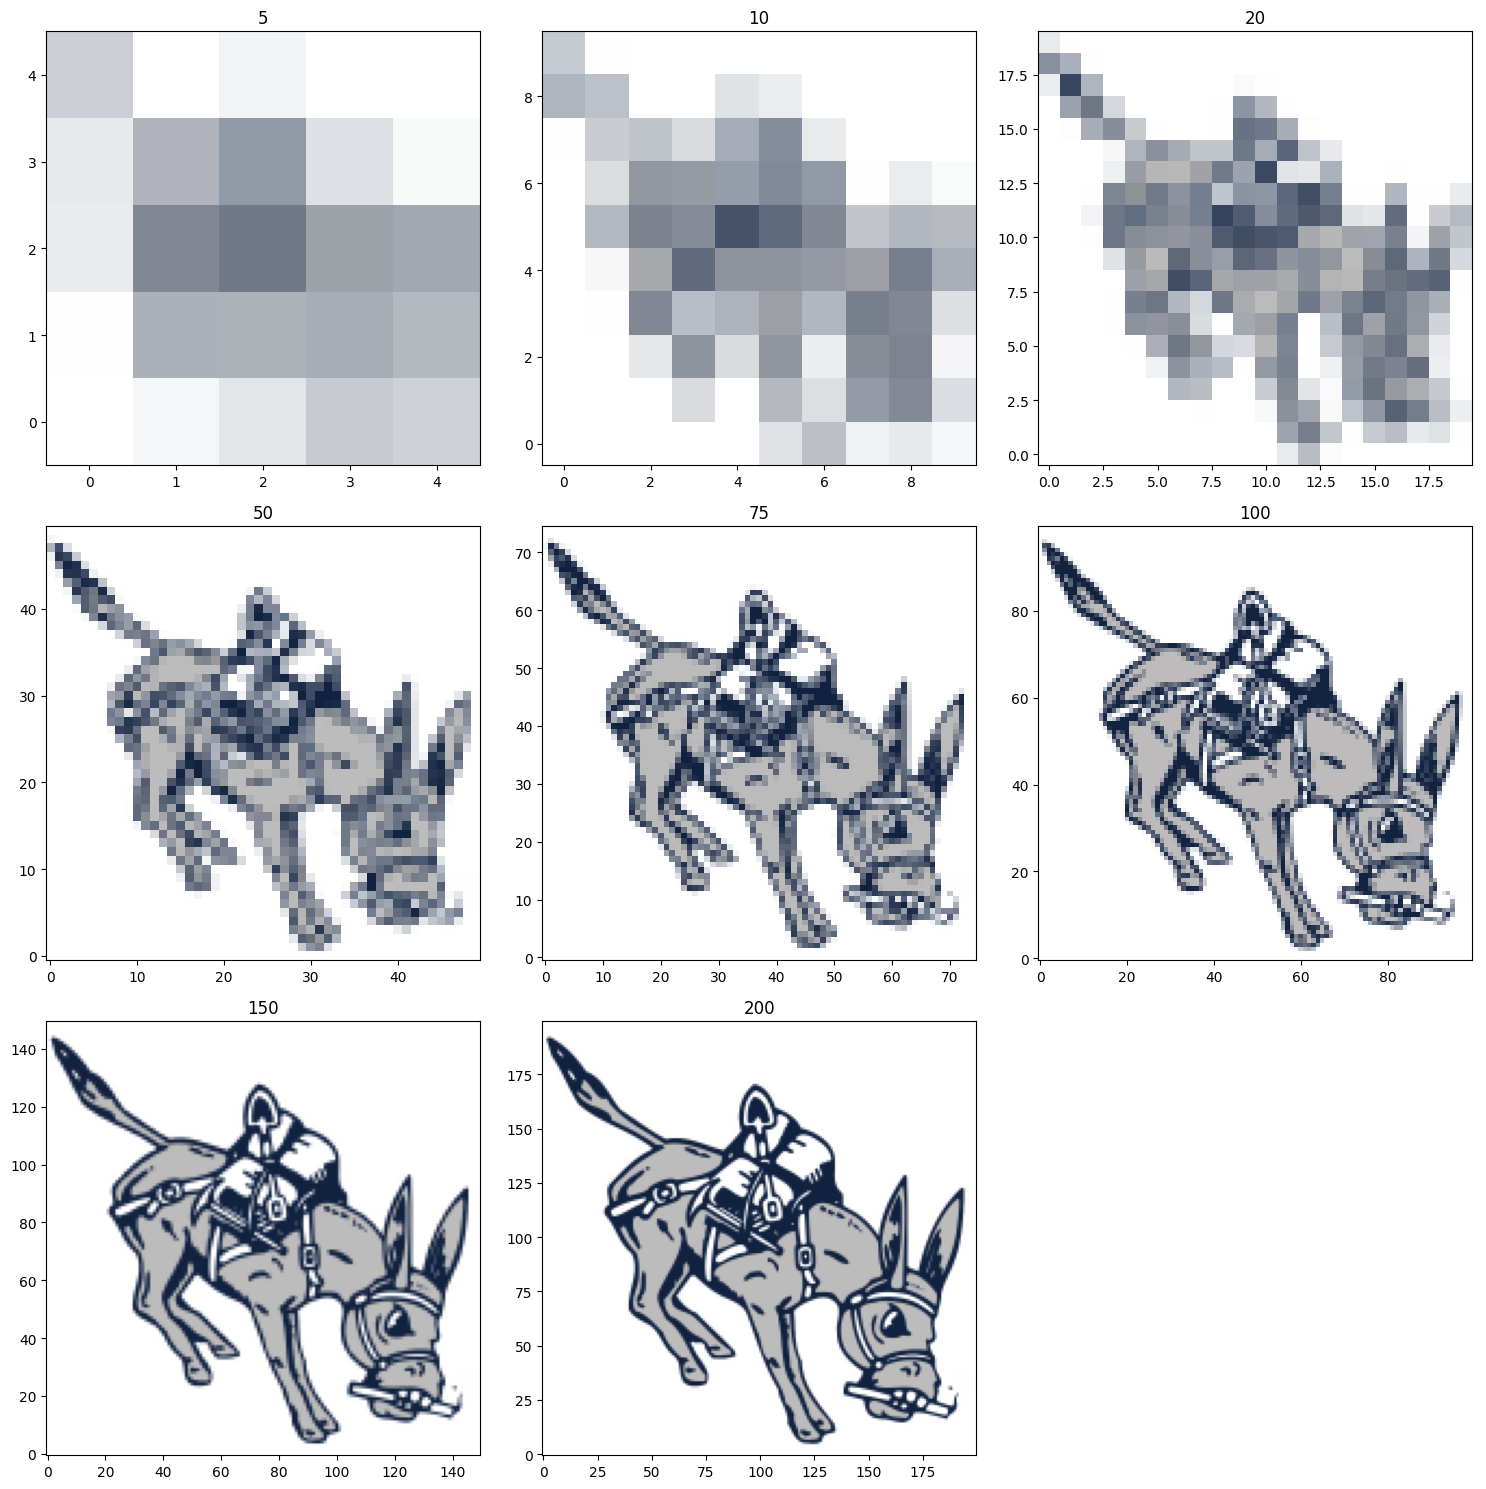

In [167]:
fig, ax = plt.subplots(3, 3, figsize=(15, 15))

ax[0, 0].imshow(blaster_5, origin="lower")
ax[0, 1].imshow(blaster_10, origin="lower")
ax[0, 2].imshow(blaster_20, origin="lower")
ax[1, 0].imshow(blaster_50, origin="lower")
ax[1, 1].imshow(blaster_75, origin="lower")
ax[1, 2].imshow(blaster_100, origin="lower")
ax[2, 0].imshow(blaster_150, origin="lower")
ax[2, 1].imshow(blaster_200, origin="lower")
ax[2, 2].axis('off')

ax[0, 0].set_title("5")
ax[0, 1].set_title("10")
ax[0, 2].set_title("20")
ax[1, 0].set_title("50")
ax[1, 1].set_title("75")
ax[1, 2].set_title("100")
ax[2, 0].set_title("150")
ax[2, 1].set_title("200")

plt.savefig("blaster_pixels.png")

plt.tight_layout()
plt.show()

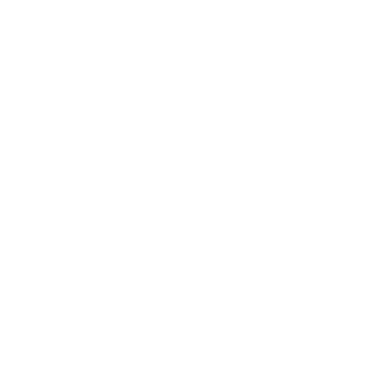

In [110]:
def show_pixel_color(image, x, y):
    pixel_color = image[y, x]
    plt.imshow([[pixel_color]], origin='lower')
    plt.axis('off')
    plt.show()

show_pixel_color(blaster_100, 15, 10)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.7178469819300268..1.0].


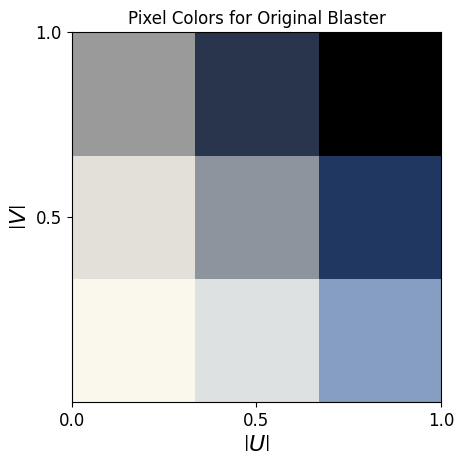

In [170]:
def get_color_goals(u_cmap):
    u_goals, v_goals = cmap_test_u_v(3, 1, 1)
    test_u, test_v, test_c, test_magu, test_combined_colors = vector_to_color(u_goals, v_goals, 1, 1, 1, u_cmap)
    return test_combined_colors

color_goals = get_color_goals(blaster_cmap_scaled)

plt.imshow(color_goals, origin='lower', extent=[0,1,0,1])
plt.xlabel("$\\left| U \\right|$", fontsize=16)
plt.ylabel("$\\left| V \\right|$", fontsize=16)
plt.xticks([0, 0.5,  1.0])
plt.yticks([0.5, 1.0])
plt.tick_params(labelsize=12)
plt.title("Pixel Colors for Original Blaster")

plt.savefig("pixel_colors_original_blaster.png")

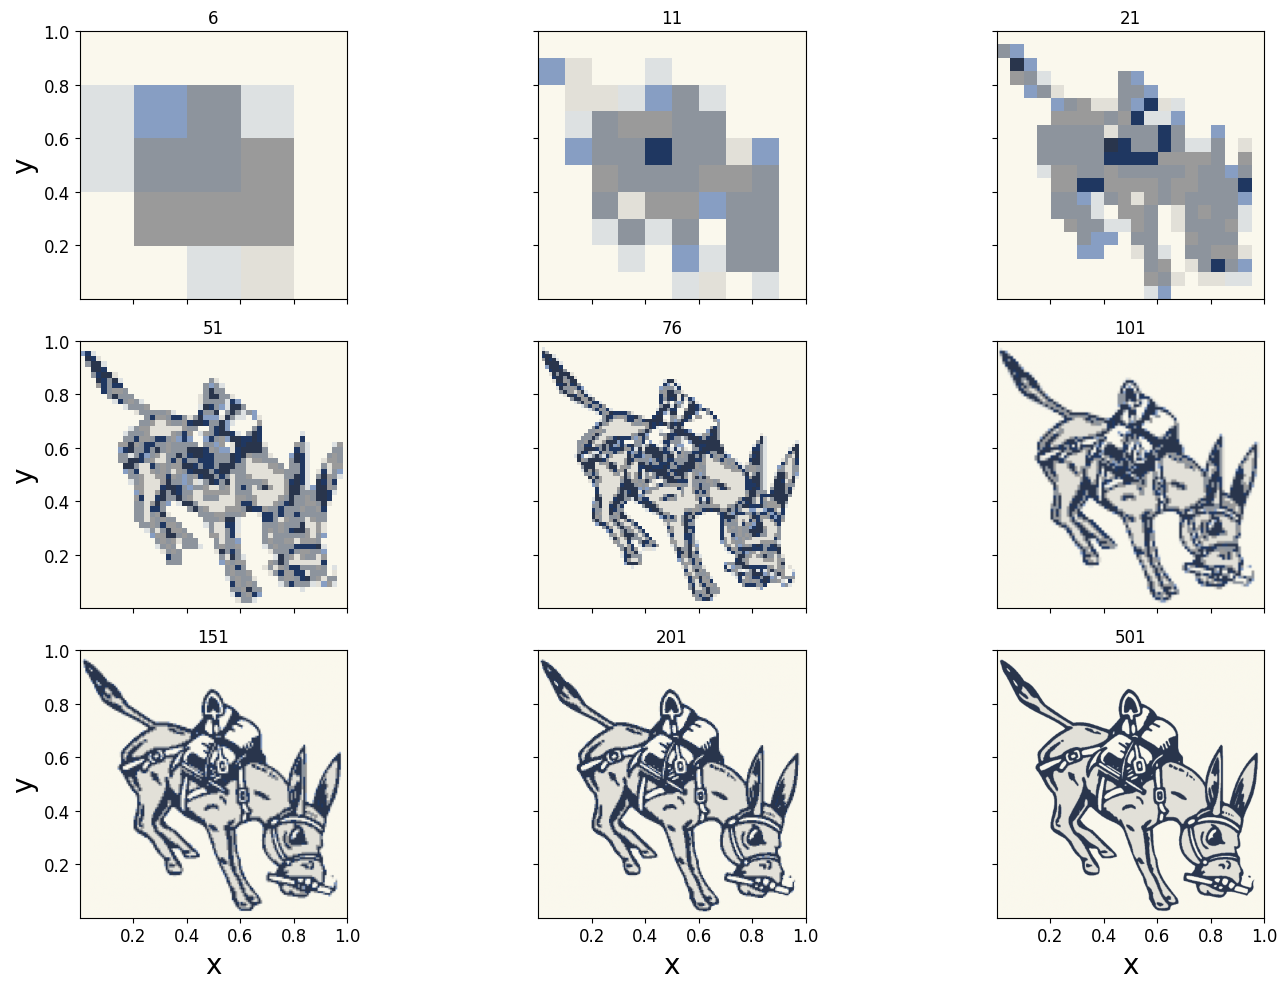

In [112]:
def project_onto_goal_colors(pixel_image_original, color_goals):
    projected_image = np.zeros_like(pixel_image_original)

    u = np.zeros([pixel_image_original.shape[0], pixel_image_original.shape[1]])
    v = np.zeros([pixel_image_original.shape[0], pixel_image_original.shape[1]])

    for i in range(pixel_image_original.shape[0]):
        for j in range(pixel_image_original.shape[1]):
            #For some reason, the boundary was reading black, too. So we fix that here.
            if i == pixel_image_original.shape[0] - 1 or j == pixel_image_original.shape[1] - 1:
                pixel = [1,1,1,1]
            else:
                pixel = pixel_image_original[i, j]
            distances = np.linalg.norm(color_goals - pixel, axis=-1)
            closest_i, closest_j = np.unravel_index(np.argmin(distances), distances.shape)
            closest_color = color_goals[closest_i, closest_j]
            projected_image[i, j] = closest_color

            u[i, j] = closest_j/2
            v[i, j] = closest_i/2
            
    return projected_image, u, v

projected_blaster_5, u_blaster_5, v_blaster_5 = project_onto_goal_colors(blaster_5, color_goals)
projected_blaster_10, u_blaster_10, v_blaster_10 = project_onto_goal_colors(blaster_10, color_goals)
projected_blaster_20, u_blaster_20, v_blaster_20 = project_onto_goal_colors(blaster_20, color_goals)
projected_blaster_50, u_blaster_50, v_blaster_50 = project_onto_goal_colors(blaster_50, color_goals)
projected_blaster_75, u_blaster_75, v_blaster_75 = project_onto_goal_colors(blaster_75, color_goals)
projected_blaster_100, u_blaster_100, v_blaster_100 = project_onto_goal_colors(blaster_100, color_goals)
projected_blaster_150, u_blaster_150, v_blaster_150 = project_onto_goal_colors(blaster_150, color_goals)
projected_blaster_200, u_blaster_200, v_blaster_200 = project_onto_goal_colors(blaster_200, color_goals)
projected_blaster_500, u_blaster_500, v_blaster_500 = project_onto_goal_colors(blaster_500, color_goals)

fig, ax = plt.subplots(3, 3, figsize=(15, 10))

ax[0, 0].imshow(projected_blaster_5, origin="lower", extent = [0,1,0,1])
ax[0, 1].imshow(projected_blaster_10, origin="lower", extent = [0,1,0,1])
ax[0, 2].imshow(projected_blaster_20, origin="lower", extent = [0,1,0,1])
ax[1, 0].imshow(projected_blaster_50, origin="lower", extent = [0,1,0,1])
ax[1, 1].imshow(projected_blaster_75, origin="lower", extent = [0,1,0,1])
ax[1, 2].imshow(projected_blaster_100, origin="lower", extent = [0,1,0,1])
ax[2, 0].imshow(projected_blaster_150, origin="lower", extent = [0,1,0,1])
ax[2, 1].imshow(projected_blaster_200, origin="lower", extent = [0,1,0,1])
ax[2, 2].imshow(projected_blaster_500, origin="lower", extent = [0,1,0,1])

ax[0, 0].set_title("6")
ax[0, 1].set_title("11")
ax[0, 2].set_title("21")
ax[1, 0].set_title("51")
ax[1, 1].set_title("76")
ax[1, 2].set_title("101")
ax[2, 0].set_title("151")
ax[2, 1].set_title("201")
ax[2, 2].set_title("501")

for i, ax_row in enumerate(ax):
    for j, ax_col in enumerate(ax_row):


        ax_col.xaxis.label.set_fontsize(20)
        ax_col.yaxis.label.set_fontsize(20)
        ax_col.set_xticks([0.2, 0.4, 0.6, 0.8, 1.0])
        ax_col.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
        ax_col.tick_params(labelsize=20)

        if j == 0:
            ax_col.set_ylabel("y")
            ax_col.set_yticklabels([0.2, 0.4, 0.6, 0.8, 1.0], fontsize=12)
        else:
            ax_col.set_yticklabels([])
        if i == 2:
            ax_col.set_xlabel("x")
            ax_col.set_xticklabels([0.2, 0.4, 0.6, 0.8, 1.0], fontsize=12)
        else:
            ax_col.set_xticklabels([])

plt.tight_layout()

# plt.savefig("projected_blaster_colors.png")
plt.show()

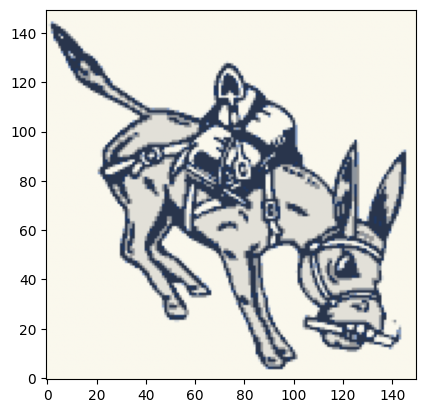

In [177]:
# example_u, example_v, example_c, example_magu, example_combined_colors = vector_to_color(example_u, example_v, 1, blaster_cmap_scaled)

b150_u, b150_v, b150_c, b150_magu, b150_combined_colors = vector_to_color(u_blaster_150, v_blaster_150, 1, 1, 1, blaster_cmap_scaled)

im = plt.imshow(b150_combined_colors, origin="lower")

plt.savefig("Vector_Field_Blaster_150.png")
plt.show()



In [114]:
def expand_appropriate_u(u):
    u = u.copy().T

In [115]:
def vectorize_u_v(u,v):
    #I think that we need to transpose this, because we read u indeces into the vector by column-major order.
    u = u.copy().T
    v = v.copy().T

    N = u.shape[0]+1

    u_vec = np.zeros(N*(N-1))
    v_vec = np.zeros(N*(N-1))

    for i in range(0,N):
        for j in range(0,N-1):
            if i == 0:
                u_vec[i+j*N] = u[i,j]-(1/2)*(u[i+1,j]-u[i,j])
            elif i == N-1:
                u_vec[i+j*N] = u[i-1,j]+(1/2)*(u[i-1,j]-u[i-2,j])
            else:
                u_vec[i+j*N] = (1/2)*(u[i,j]+u[i-1,j])
    
    for i in range(0, N-1):
        for j in range(0,N):
            if j == 0:
                v_vec[i+j*(N-1)] = v[i,j]-(1/2)*(v[i,j+1]-v[i,j])
            elif j == N-1:
                v_vec[i+j*(N-1)] = v[i,j-1]+(1/2)*(v[i,j-1]-v[i,j-2])
            else:
                v_vec[i+j*(N-1)] = (1/2)*(v[i,j]+v[i,j-1])


    #Assuming we got this correct -- which is probably unlikely until we make a change -- we want to also put in 0's for our lagrangian, the pressure vector.

    p_vec = np.zeros((N-1)*(N-1))
    return np.concatenate((u_vec, v_vec, p_vec))

u_blaster_5_vec = vectorize_u_v(u_blaster_5, v_blaster_5)
u_blaster_10_vec = vectorize_u_v(u_blaster_10, v_blaster_10)
u_blaster_20_vec = vectorize_u_v(u_blaster_20, v_blaster_20)
u_blaster_50_vec = vectorize_u_v(u_blaster_50, v_blaster_50)
u_blaster_75_vec = vectorize_u_v(u_blaster_75, v_blaster_75)
u_blaster_100_vec = vectorize_u_v(u_blaster_100, v_blaster_100)
u_blaster_150_vec = vectorize_u_v(u_blaster_150, v_blaster_150)
u_blaster_200_vec = vectorize_u_v(u_blaster_200, v_blaster_200)
u_blaster_500_vec = vectorize_u_v(u_blaster_500, v_blaster_500)




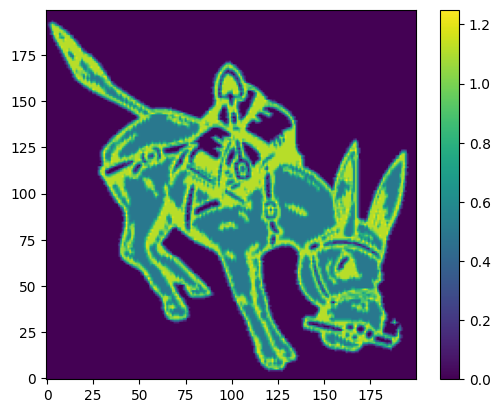

In [116]:
#Now we see if we did it correctly be re-interpreting it as we did 

fig, ax = plt.subplots()

u_50, v_50, p_50 = interpret_x_for_graph(u_blaster_200_vec, 201)

mag_u = np.sqrt(u_50**2 + v_50**2)

im = ax.imshow(mag_u, 
    origin="lower",
    )

cbar = fig.colorbar(im, ax=ax)
im.set_cmap("viridis")

In [117]:
N = 201


def create_stokes_system(N):
    A = create_blank_stgrd_stokes_matrix(N)
    b = np.zeros((A.shape[0],))
    h = 1/(N-1)

    def dumb_gs(x, y):
        return 0

    laplacian_U(A, N, h, b, dumb_gs, dumb_gs, 0, 1, 0, 1, dumb_gs, dumb_gs)
    laplacian_V(A, N, h, b, dumb_gs, dumb_gs, 0, 1, 0, 1, dumb_gs, dumb_gs)
    divergence(A, N, h, b)


    return A, b

A_5 , b_5 = create_stokes_system(6)
A_10, b_10 = create_stokes_system(11)
A_20, b_20 = create_stokes_system(21)
A_50, b_50 = create_stokes_system(51)
A_75, b_75 = create_stokes_system(76)
A_100, b_100 = create_stokes_system(101)
A_150, b_150 = create_stokes_system(151)
A_200, b_200 = create_stokes_system(201)

In [118]:
b_goal_5 = A_5 @ u_blaster_5_vec
b_goal_10 = A_10 @ u_blaster_10_vec
b_goal_20 = A_20 @ u_blaster_20_vec
b_goal_50 = A_50 @ u_blaster_50_vec
b_goal_75 = A_75 @ u_blaster_75_vec
b_goal_100 = A_100 @ u_blaster_100_vec
b_goal_150 = A_150 @ u_blaster_150_vec
b_goal_200 = A_200 @ u_blaster_200_vec

In [119]:
#Need to set the last (N-1)*(N-1) to 0.
for N in [6, 11, 21, 51, 76, 101, 151, 201]:
    globals()[f"b_goal_{N-1}"][-(N-1)*(N-1):] = 0

In [120]:
for N in [6, 11, 21, 51, 76, 101, 151, 201]:
    A = globals()[f"A_{N-1}"]
    b_goal = globals()[f"b_goal_{N-1}"]
    globals()[f"fluid_blaster_{N-1}"] = sp.sparse.linalg.spsolve(A.tocsr(), b_goal) 

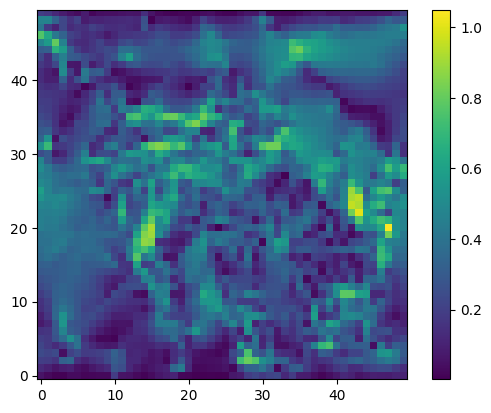

In [121]:
fig, ax = plt.subplots()

u_fluid_blaster, v_fluid_blaster, p_fluid_blaster = interpret_x_for_graph(fluid_blaster_50, 51)

mag_u_fb = np.sqrt(u_fluid_blaster**2 + v_fluid_blaster**2)
max_u_fb = np.max(mag_u_fb)

im = ax.imshow(mag_u_fb, 
    origin="lower",
    )

cbar = fig.colorbar(im, ax=ax)
im.set_cmap("viridis")

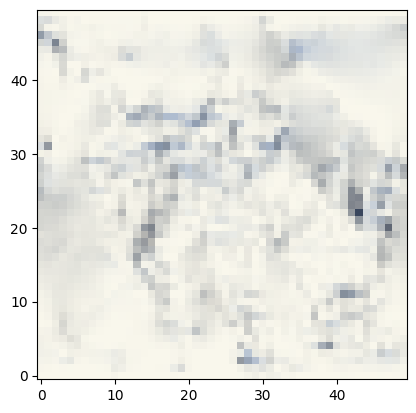

In [122]:
fb_u, fb_v, fb_c, fb_magu, fb_combined_colors = vector_to_color(u_fluid_blaster, v_fluid_blaster, max_u_fb, blaster_cmap_scaled)

im = plt.imshow(fb_combined_colors, origin="lower")
plt.show()

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-6.051586962000837..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-7.517569632737625..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.5582584696281573..1.0].


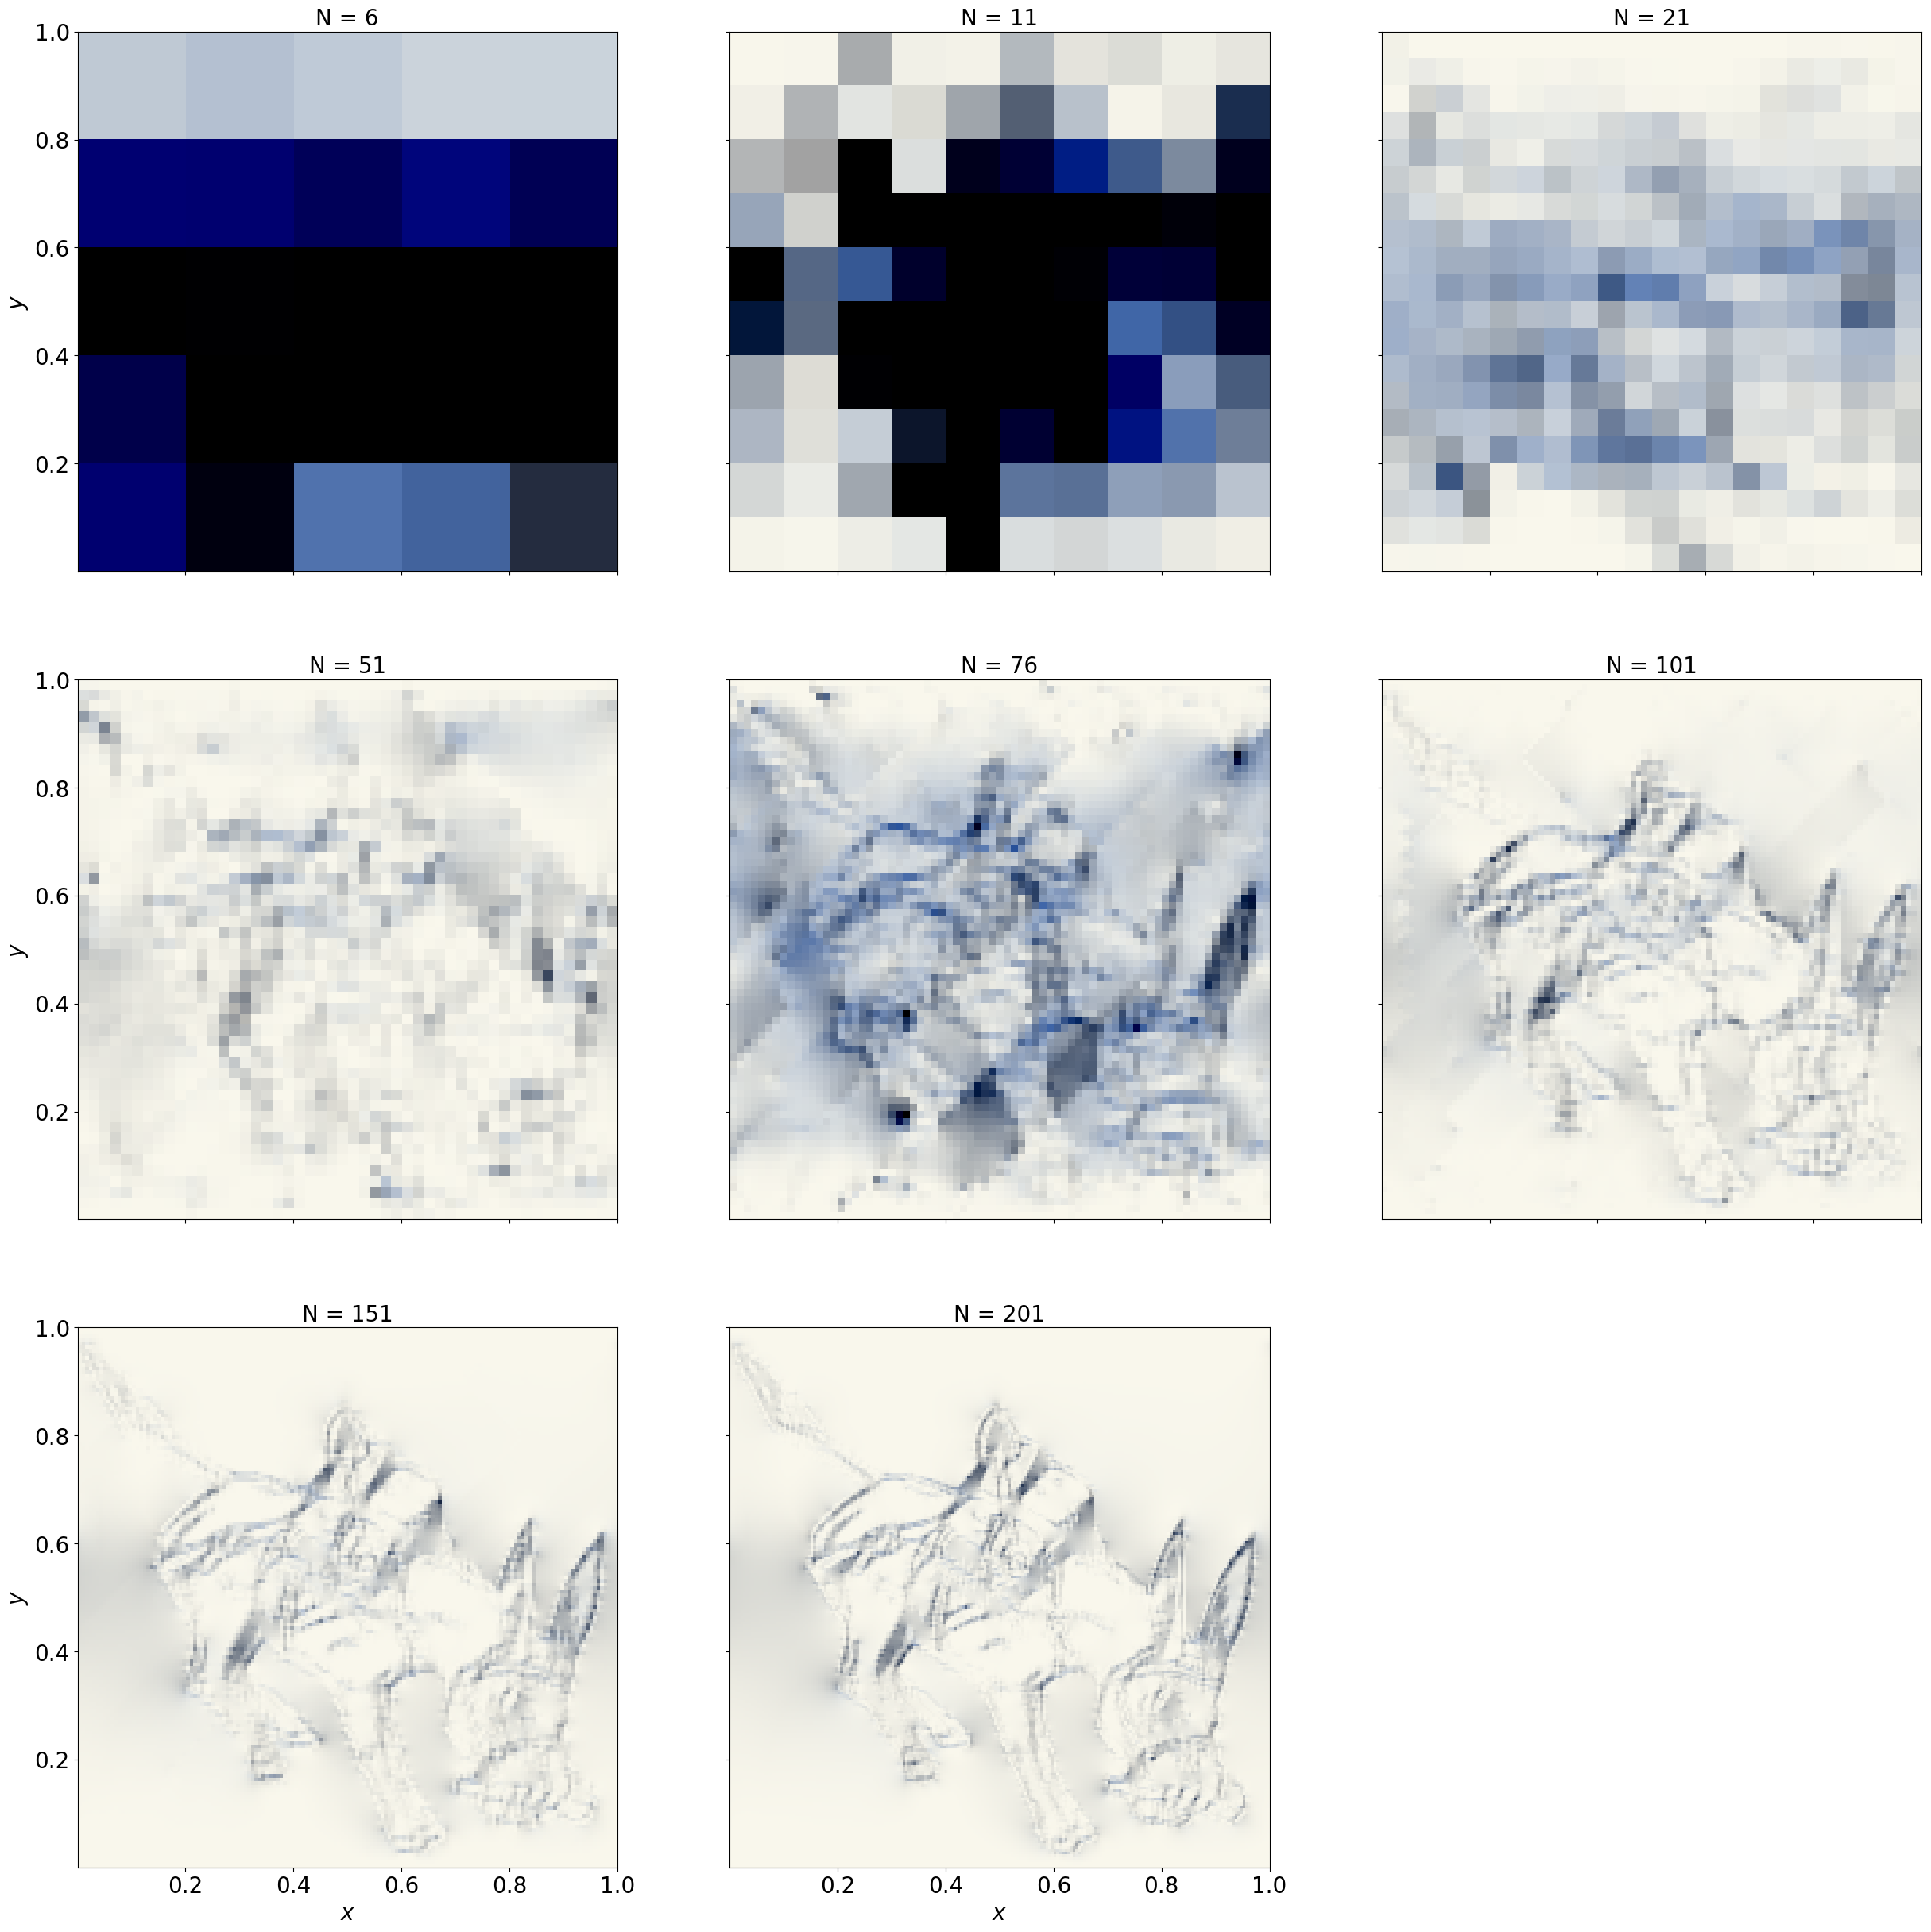

In [123]:
fig, ax = plt.subplots(3, 3, sharex=True, sharey=True, figsize=(30, 30))


for i, N in enumerate([6, 11, 21, 51, 76, 101, 151, 201]):
    u_fluid_blaster, v_fluid_blaster, p_fluid_blaster = interpret_x_for_graph(globals()[f"fluid_blaster_{N-1}"], N)
    max_u_fb = np.max(np.sqrt(u_fluid_blaster**2 + v_fluid_blaster**2))
    
    fb_u, fb_v, fb_c, fb_magu, fb_combined_colors = vector_to_color(u_fluid_blaster, v_fluid_blaster, max_u_fb, blaster_cmap_scaled)


    ax[i // 3, i % 3].imshow(fb_combined_colors, origin="lower", extent=[0, 1, 0, 1])
    ax[i // 3, i % 3].set_title(f"N = {N}")

ax[2, 2].axis('off')

#Set all of the axis titles to be the same font size
for ax_row in ax:
    for ax_col in ax_row:
        ax_col.title.set_fontsize(20)

#Set all of the x, y labels to be the same font size
for i, ax_row in enumerate(ax):
    for j, ax_col in enumerate(ax_row):
        if j == 0:
            ax_col.set_ylabel("$y$", fontsize=28)
        if i == len(ax) - 1:
            ax_col.set_xlabel("$x$", fontsize=28)


        ax_col.xaxis.label.set_fontsize(20)
        ax_col.yaxis.label.set_fontsize(20)
        ax_col.set_xticks([0.2, 0.4, 0.6, 0.8, 1.0])
        ax_col.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
        ax_col.tick_params(labelsize=20)

#save this figure
# fig.savefig("fluid_blaster.png", bbox_inches='tight')